In [55]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
import random

from torchvision import transforms
from sklearn.model_selection import train_test_split


## Подготовка данных

In [2]:
train_df = pd.read_csv("ML9_dataset/Train.csv")
test_df = pd.read_csv("ML9_dataset/Test.csv")
sample = pd.read_csv("ML9_dataset/SampleSubmission.csv")

In [34]:
ran_rows = random.sample(range(0, train_df.shape[0]), 10)

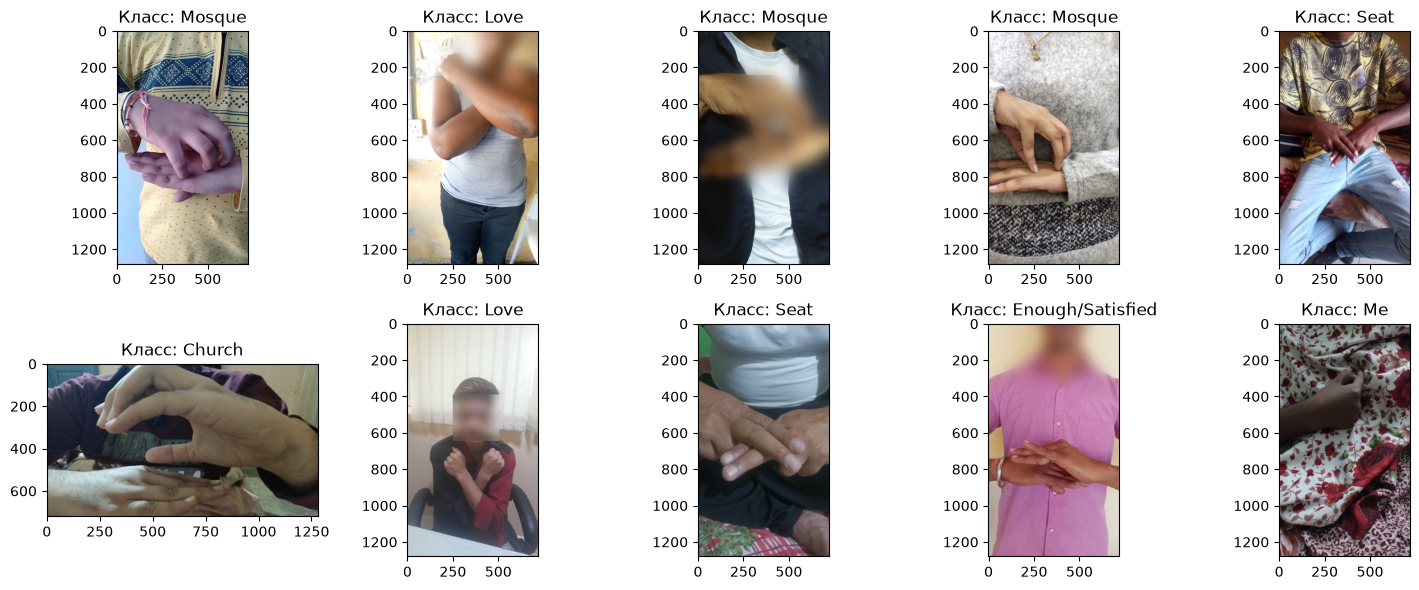

In [50]:
fig, ax = plt.subplots(2, 5, figsize=(15, 6))
ax = ax.flatten()   
sizze = list()
for i, (ind, row) in enumerate(train_df.iloc[ran_rows].iterrows()):
    img_name = row['img_IDS']
    target = row['Label']
    
    img_path = os.path.join('ML9_dataset/Images/', img_name + '.jpg')

    if os.path.exists(img_path):
        img = Image.open(img_path)
        sizze.append(img.size)
        ax[i].imshow(img)
        ax[i].set_title(f"Класс: {target}")

plt.tight_layout()
plt.show()

In [52]:
sizze

[(720, 1280),
 (720, 1280),
 (720, 1280),
 (720, 1280),
 (720, 1280),
 (1280, 720),
 (720, 1280),
 (720, 1280),
 (720, 1280),
 (720, 1280)]

Тут я заметила, что изображения слишком большие, поэтому ниже применила Resize.

In [57]:
Train_transform = transforms.Compose([
    transforms.Resize(256), # маленькая сторона 256
    transforms.RandomCrop(size=224, padding=4), # обрезка размера 224
    transforms.RandomRotation(degrees=(-10, 10)), # поворот
    transforms.ColorJitter(brightness=0.2, contrast=0.2), # ±20% яркость и контраст
    transforms.RandomPerspective(distortion_scale=0.2, p=0.25, fill=(0,0,0)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

Это аугментации, те расширение данных за счет самих данных, но без использования лишней памяти.
\
Я использовала:
- обрезку, чтобы жест не всегда был в центре
- поворот, по горизонтали, но не сильный (от -10 до 10 градусов), чтобы не менялась суть жестов
- изменение свойств, таких как яркость и контростность
- перспеутива, чтобы жесты были под углом в 25% случаев

Все остальные преобразования нужны для дальнейшей корректной обработки данных.

In [56]:
train_data, val_data = train_test_split(train_df, test_size=0.33, stratify=train_df['Label']) # stratify - сохранение пропорций каждого класса    

In [ ]:
!git add m